# 3.04 · Physics-informed neural networks

*Topic 3 is under development: content and numbering may still change.*

**Before this:** [2.10](2-10_loss_functions_optimisation.ipynb) (losses, Adam), [2.13](2-13_model_errors_cd_cp.ipynb) (model error), [2.17](2-17_jax_differentiable.ipynb) (automatic differentiation), [3.02](3-02_neural_networks_resnets.ipynb) (neural networks) ·
**You will be able to:** build a PINN for an ODE and train it; set up an inverse PINN that estimates parameters;
recognise its three failure modes (stiffness, spectral bias, loss weights); check a PINN answer by re-solving with a
trusted solver · **Optional sections:** 4 (spectral bias).

A physics-informed neural network (PINN) replaces the ODE solver by a small neural network. The network is trained so
that its curve obeys the differential equation at many chosen times and starts from the right initial value. In an
inversion the unknown friction parameters are trained together with the network, so one optimisation fits the data and
the physics at once. Fukushima et al. (2025, 2026) used PINNs to estimate frictional-parameter fields on the Bungo
Channel slow-slip patch from geodetic data. This notebook builds a PINN from scratch on the single-patch afterslip
model of `bayeskit/afterslip.py`. That model has an exact solution, so every PINN answer can be graded: first the
forward problem, then the inverse problem, then the ways it fails.

**Words this notebook defines:** physics-informed neural network (PINN), collocation point, residual, physics (ODE)
loss, initial-condition loss, data loss, loss weight, soft constraint, units of the residual, log-time coordinate,
stiffness, spectral bias, inverse PINN, Bayesian PINN (B-PINN).

The PINN idea is usually credited to Raissi, Perdikaris & Karniadakis (2019), cited here for the idea only. Quotes from
Fukushima et al. are verbatim, with the page numbers of the published PDFs (symbols typeset).

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| single-patch afterslip, forward (sections 2-3) | the network weights (3 hidden layers of 32, count printed below) | none: only the ODE and the initial value | $\dot s = 2v_0\sinh\big((\Delta\tau - k s)/a\sigma\big)$, $s(0) = 0$, $u = g\,s$ | nonlinear |
| spectral-bias toy (section 4) | the network weights | 256 samples of $\sin\pi x + 0.5\sin 8\pi x$ | none (curve fitting) | n/a |
| single-patch afterslip, inverse (sections 5-7) | $\ln a\sigma$, $\ln v_0$ (+ the network weights) | 40 GPS epochs, day 1 to year 1, σ = 2 mm | as above, $\Delta\tau$ = 2.5 MPa known | nonlinear |

Units as in `bayeskit/afterslip.py`: time in years, slip in metres, stress in MPa, $v_0$ in m/yr, stiffness
$k$ = 3 MPa/m, surface factor $g$ = 0.6.

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
T0 = time.time()
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S
from bayeskit import afterslip as A
import jax, jax.numpy as jnp
from jax.flatten_util import ravel_pytree
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_uniform
from numpyro.diagnostics import split_gelman_rubin

K, G = A.SP_DEFAULTS["k"], A.SP_DEFAULTS["g"]           # 3 MPa/m, 0.6
SIG = 0.002                                               # GPS noise, m
C_PINN, C_LIN, C_NUTS, C_TRUE = S.ORANGE, S.VIOLET, S.COLORS["nuts"], S.INK
print("jax", jax.__version__, "| numpyro", numpyro.__version__, "| float64:", jax.config.jax_enable_x64)

jax 0.10.0 | numpyro 0.21.0 | float64: True


## 1. The black box and its exact solution

**In plain words.** The earthquake raises the shear stress on a patch below it. Rate-strengthening friction (friction
that resists more strongly the faster the patch slips, so slip stays stable instead of running away) lets the
patch slip fast at first; the slip itself relieves the stress, so the patch slows down. A GPS station above records
a curve that rises quickly over the first days and keeps creeping for a year.

**Precisely.** With stress $\tau$, slip $s$ and slip rate $v$,
$$v = 2v_0\sinh(\tau/a\sigma),\qquad \dot\tau = -k\,v,\qquad \tau(0) = \Delta\tau,\quad s(0) = 0,\qquad u(t) = g\,s(t),$$
so $\tau = \Delta\tau - k s$. This single ODE separates (everything with $\tau$ can be moved to one side and
everything with $t$ to the other, and both sides integrated). Because $\frac{d}{d\tau}\big[a\sigma\ln\tanh\frac{\tau}{2a\sigma}\big] = \frac{1}{\sinh(\tau/a\sigma)}$,
$$\tanh\frac{\tau(t)}{2a\sigma} = \tanh\frac{\Delta\tau}{2a\sigma}\;e^{-2kv_0t/a\sigma},\qquad s(t) = \frac{\Delta\tau - \tau(t)}{k}.$$
For $\Delta\tau \gg a\sigma$ it reduces to the familiar logarithm $s \approx \frac{a\sigma}{k}\ln(1 + t/t_c)$ with the
characteristic time $t_c = a\sigma/(k v_+)$ and initial slip rate $v_+ = v_0e^{\Delta\tau/a\sigma}$.
The module's solver (`A.single_patch_series`, diffrax Kvaerno5) is the "black box"; the closed form is our answer key.
We code it in a numerically stable way (no $1 - \tanh$ cancellation) and compare.

In [2]:
def u_exact(theta, t):
    """Closed-form surface displacement (m) of the single patch, sinh friction (not the log approximation)."""
    a_s, v0, dtau = jnp.exp(theta[0]), jnp.exp(theta[1]), theta[2]
    z = dtau / (2 * a_s)
    q = 2 * jnp.exp(-2 * z) / (1 + jnp.exp(-2 * z))          # 1 - tanh(z) without cancellation
    e = jnp.exp(-2 * K * v0 / a_s * t)
    tau = a_s * jnp.log((1 + (1 - q) * e) / (-jnp.expm1(-2 * K * v0 / a_s * t) + q * e))   # 2 a_s artanh(tanh(z) e)
    return G * (dtau - tau) / K


TRUE = np.array([np.log(0.5), np.log(0.03), 2.5])           # a_sigma 0.5 MPa, v0 0.03 m/yr, dtau 2.5 MPa
t_obs = jnp.asarray(A.T_OBS)
solve = jax.jit(lambda th: A.single_patch_series(th, t_obs))
u_box = solve(jnp.asarray(TRUE)).block_until_ready()
t0 = time.time()
for _ in range(20):
    u_box = solve(jnp.asarray(TRUE)).block_until_ready()
T_SOLVE = (time.time() - t0) / 20
u_ref = u_exact(jnp.asarray(TRUE), t_obs)
print(f"black box (diffrax) vs closed form at the 40 epochs: max difference {1e3 * float(jnp.max(jnp.abs(u_box - u_ref))):.1e} mm")
print(f"log formula vs closed form:                          max difference "
      f"{1e3 * np.max(np.abs(A.single_patch_log_formula(TRUE, A.T_OBS) - np.asarray(u_ref))):.2f} mm")
th_box = A.sample_theta(np.random.default_rng(0), 300)
u_b = np.asarray(jax.jit(jax.vmap(solve))(jnp.asarray(th_box)))
u_e = np.asarray(jax.vmap(lambda th: u_exact(th, t_obs))(jnp.asarray(th_box)))
print(f"300 random parameter sets over the prior box: max |diffrax - closed form| = {1e3 * np.abs(u_b - u_e).max():.1e} mm"
      f" (largest displacement {1e3 * u_e.max():.0f} mm)")
print(f"one black-box solve: {1e3 * T_SOLVE:.1f} ms")

black box (diffrax) vs closed form at the 40 epochs: max difference 6.5e-07 mm
log formula vs closed form:                          max difference 1.15 mm


300 random parameter sets over the prior box: max |diffrax - closed form| = 2.6e-05 mm (largest displacement 973 mm)
one black-box solve: 2.6 ms


**Worked example.** For the reference patch ($a\sigma$ = 0.5 MPa, $v_0$ = 0.03 m/yr, $\Delta\tau$ = 2.5 MPa):
(1) $\Delta\tau/a\sigma$; (2) $v_+ = v_0e^{\Delta\tau/a\sigma}$; (3) $t_c = a\sigma/(kv_+)$; (4) $u$(1 yr) from the
closed form and from the logarithm. The code prints each step.

In [3]:
a_s, v0, dtau = np.exp(TRUE[0]), np.exp(TRUE[1]), TRUE[2]
R_TRUE = dtau / a_s
v_plus = v0 * np.exp(R_TRUE)
t_c = a_s / (K * v_plus)
print(f"(1) dtau / a_sigma = {dtau} / {a_s} = {R_TRUE:.2f}")
print(f"(2) v+ = {v0} * exp({R_TRUE:.2f}) = {v_plus:.3f} m/yr")
print(f"(3) t_c = {a_s} / ({K} * {v_plus:.3f}) = {t_c:.4f} yr = {365.25 * t_c:.1f} days")
print(f"(4) u(1 yr): closed form {1e3 * float(u_exact(jnp.asarray(TRUE), 1.0)):.1f} mm, "
      f"log formula g a_sigma / k ln(1 + 1/t_c) = {1e3 * G * a_s / K * np.log1p(1 / t_c):.1f} mm")

(1) dtau / a_sigma = 2.5 / 0.5 = 5.00
(2) v+ = 0.029999999999999995 * exp(5.00) = 4.452 m/yr
(3) t_c = 0.5 / (3.0 * 4.452) = 0.0374 yr = 13.7 days
(4) u(1 yr): closed form 331.0 mm, log formula g a_sigma / k ln(1 + 1/t_c) = 332.2 mm


saved figures/3-04_black_box.png


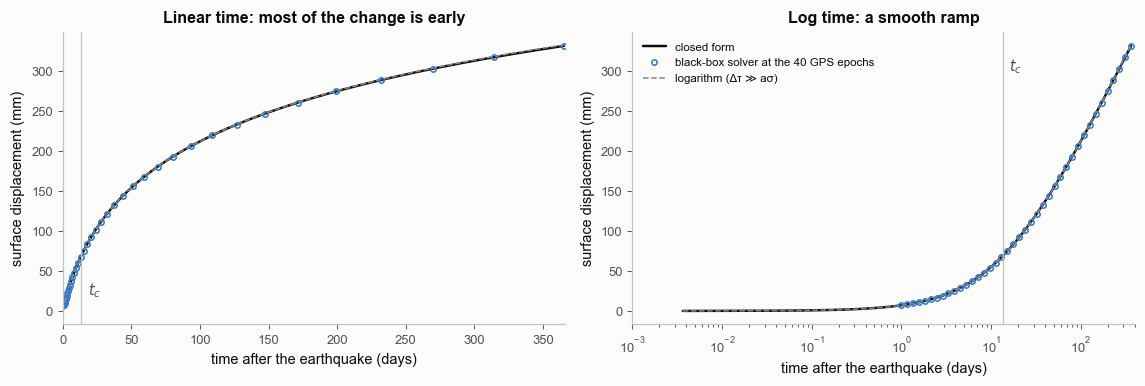

In [4]:
tt = np.geomspace(1e-5, 1.0, 600)
u_tt = np.asarray(u_exact(jnp.asarray(TRUE), jnp.asarray(tt)))
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, xs_ in zip(axs, ["linear", "log"]):
    ax.plot(tt * 365.25, 1e3 * u_tt, color=C_TRUE, lw=1.6, label="closed form")
    ax.plot(A.T_OBS * 365.25, 1e3 * np.asarray(u_box), "o", ms=3.5, mfc="none", color=C_NUTS, label="black-box solver at the 40 GPS epochs")
    ax.plot(tt * 365.25, 1e3 * A.single_patch_log_formula(TRUE, tt), color=S.MUTED, lw=1.0, ls="--", label="logarithm (Δτ ≫ aσ)")
    ax.axvline(365.25 * t_c, color=S.AXIS, lw=0.8)
    ax.set_xscale(xs_); ax.set_xlabel("time after the earthquake (days)"); ax.set_ylabel("surface displacement (mm)")
axs[0].set_xlim(0, 366); axs[1].set_xlim(1e-3, 400)
axs[0].text(365.25 * t_c + 5, 20, "$t_c$", color=S.INK2)
axs[1].text(365.25 * t_c * 1.15, 300, "$t_c$", color=S.INK2)
axs[0].set_title("Linear time: most of the change is early")
axs[1].set_title("Log time: a smooth ramp")
axs[1].legend(loc="upper left", fontsize=7.5)
fig.tight_layout()
bk.savefig(fig, "3-04_black_box")
plt.show()

**How to read it.** The same curve on two time axes. On the linear axis (left) the displacement shoots up within the
first weeks; on the log axis (right) it is a gentle ramp that starts at about $t_c$. Black-box solver and closed form
agree to the difference printed above. The logarithm (dashed) drifts away late, when the stress has dropped to a few
times $a\sigma$ and $\sinh$ is no longer an exponential.

**Common misreadings.**
* "Afterslip is the logarithm." The logarithm is the early-time limit of this model; the late curve bends below it.

**In practice.** Stress-driven afterslip models of this kind, with friction that varies over a fault, are used to
interpret postseismic GPS time series; here the model is reduced to one patch (`bayeskit/afterslip.py`).

## 2. A PINN by hand: the forward problem

**In plain words.** A solver marches the equation forward in small time steps. A PINN instead guesses the whole curve
at once, with a small neural network whose input is time. It then adjusts the network until (i) the curve's slope
equals what the friction law demands at many chosen times, called *collocation points*, and (ii) the curve starts at
zero. Nothing is learned from data yet: the equation itself is the training signal.

**Precisely.** Write the slip in units of $a\sigma/k$, $y = ks/a\sigma$, and use the log of time, $\xi = \ln t$, as the
network input. With $R = \Delta\tau/a\sigma$ the ODE becomes
$$\frac{dy}{d\xi} = t\,\frac{dy}{dt} = e^{\xi - \ln t_c}\big(e^{-y} - e^{y - 2R}\big).$$
The network $y_w(\xi)$ (weights $w$) has a *residual* $r_w(\xi) = \frac{dy_w}{d\xi} - e^{\xi - \ln t_c}(e^{-y_w} - e^{y_w-2R})$, which is zero
for the exact solution. The loss is
$$L(w) = \underbrace{\frac{1}{N_c}\sum_{j=1}^{N_c} r_w(\xi_j)^2}_{L_\text{ode}} + \underbrace{y_w(\xi_0)^2}_{L_\text{ic}},$$
with $N_c$ = 128 collocation points spread evenly in $\xi$ from $t_0 = 10^{-5}$ yr (five minutes) to one year. The
derivative $dy_w/d\xi$ is the derivative of the network with respect to its *input*, computed by autodiff (2.17;
`jax.grad(net, argnums=1)`). The initial condition is imposed at $t_0$ instead of $t = 0$ (log time cannot reach zero);
the code prints the displacement this neglects. Training uses Adam, written out below in a dozen lines.

In [5]:
def init_mlp(key, sizes):
    """Weights with Xavier-normal scaling, zero biases."""
    params = []
    for m, n in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append((jax.random.normal(sub, (m, n)) * np.sqrt(2.0 / (m + n)), jnp.zeros(n)))
    return params


def mlp(params, x):
    """A scalar input x -> tanh hidden layers -> a scalar output."""
    h = jnp.atleast_1d(x)
    for W, b in params[:-1]:
        h = jnp.tanh(h @ W + b)
    W, b = params[-1]
    return (h @ W + b)[0]


def adam(loss, params, n_steps, lr, state=None, i0=0, b1=0.9, b2=0.999, eps=1e-8):
    """Adam by hand. loss(params) -> (value, aux). Returns params, optimiser state (to resume), history of (value, aux)."""
    flat, unravel = ravel_pytree(params)
    m, v = (jnp.zeros_like(flat), jnp.zeros_like(flat)) if state is None else state
    value_and_grad = jax.value_and_grad(lambda f: loss(unravel(f)), has_aux=True)

    def step(carry, i):
        f, m, v = carry
        (L, aux), g = value_and_grad(f)
        m = b1 * m + (1 - b1) * g                                    # running mean of the gradient
        v = b2 * v + (1 - b2) * g ** 2                               # running mean of its square
        f = f - lr(i) * (m / (1 - b1 ** (i + 1))) / (jnp.sqrt(v / (1 - b2 ** (i + 1))) + eps)
        return (f, m, v), (L, aux)

    (f, m, v), hist = jax.lax.scan(step, (flat, m, v), i0 + jnp.arange(n_steps))
    return unravel(f), (m, v), hist


SIZES = [1, 32, 32, 32, 1]
N_STEPS = 20000
lr_fwd = lambda i: 3e-3 * 0.1 ** (i / N_STEPS)                    # learning rate decays tenfold over the run
XI0, XI1 = np.log(1e-5), 0.0
XI_C = jnp.linspace(XI0, XI1, 128)                                # collocation points, even in log time
T_C = jnp.linspace(0.0, 1.0, 128)                                 # the same number, even in linear time (section 3)
to_unit = lambda xi: 2 * (xi - XI0) / (XI1 - XI0) - 1             # network input scaled to [-1, 1]
y_log = lambda p, xi: mlp(p, to_unit(xi))
y_lin = lambda p, t: mlp(p, 2 * t - 1)


def loss_log(p, ln_tc, R):
    def r(xi):
        dy = jax.grad(y_log, argnums=1)(p, xi)
        y = y_log(p, xi)
        return dy - jnp.exp(xi - ln_tc - y) + jnp.exp(xi - ln_tc + y - 2 * R)
    L_ode, L_ic = jnp.mean(jax.vmap(r)(XI_C) ** 2), y_log(p, XI0) ** 2
    return L_ode + L_ic, (L_ode, L_ic)


def loss_lin(p, ln_tc, R):
    def r(t):                                                     # t_c dy/dt - (...): dimensionless, like the log version
        dy = jax.grad(y_lin, argnums=1)(p, t)
        y = y_lin(p, t)
        return jnp.exp(ln_tc) * dy - (jnp.exp(-y) - jnp.exp(y - 2 * R))
    L_ode, L_ic = jnp.mean(jax.vmap(r)(T_C) ** 2), y_lin(p, 0.0) ** 2
    return L_ode + L_ic, (L_ode, L_ic)


p0 = init_mlp(jax.random.PRNGKey(0), SIZES)
print("network weights and biases:", ravel_pytree(p0)[0].size)
print(f"displacement neglected by starting at t0 = 1e-5 yr: {1e3 * float(u_exact(jnp.asarray(TRUE), 1e-5)):.4f} mm (sigma = 2 mm)")
ln_tc_true = np.log(t_c)

# train in segments so that we can look at the curve along the way
run = jax.jit(lambda p, st, i0, n: adam(lambda q: loss_log(q, ln_tc_true, R_TRUE), p, n, lr_fwd, st, i0), static_argnums=3)
seg_ends, snaps, hists, p, st = [300, 1500, 5000, N_STEPS], {}, [], p0, None
t0 = time.time()
i0 = 0
for end in seg_ends:
    p, st, h = run(p, st, i0, end - i0)
    hists.append(h); i0 = end
    snaps[end] = G * a_s / K * np.asarray(jax.vmap(lambda x: y_log(p, x))(jnp.log(jnp.asarray(tt))))
jax.block_until_ready(p)
T_PINN_FWD = time.time() - t0
p_fwd = p
L_hist = np.concatenate([np.asarray(h[0]) for h in hists])
Lode_hist = np.concatenate([np.asarray(h[1][0]) for h in hists]); Lic_hist = np.concatenate([np.asarray(h[1][1]) for h in hists])
err_fwd = np.abs(snaps[N_STEPS] - u_tt)
m_gps = tt >= 1 / 365.25
print(f"training: {N_STEPS} Adam steps in {T_PINN_FWD:.1f} s (one black-box solve: {1e3 * T_SOLVE:.1f} ms, "
      f"ratio {T_PINN_FWD / T_SOLVE:.0f})")
print(f"final L_ode {Lode_hist[-1]:.1e}, L_ic {Lic_hist[-1]:.1e}")
for end in seg_ends:
    print(f"after {end:5d} steps: largest |PINN - exact| between day 1 and year 1 = {1e3 * np.abs(snaps[end] - u_tt)[m_gps].max():8.3f} mm")

network weights and biases: 2209
displacement neglected by starting at t0 = 1e-5 yr: 0.0267 mm (sigma = 2 mm)


training: 20000 Adam steps in 4.0 s (one black-box solve: 2.6 ms, ratio 1544)
final L_ode 6.7e-07, L_ic 3.1e-13
after   300 steps: largest |PINN - exact| between day 1 and year 1 =  210.351 mm
after  1500 steps: largest |PINN - exact| between day 1 and year 1 =  190.634 mm
after  5000 steps: largest |PINN - exact| between day 1 and year 1 =    0.623 mm
after 20000 steps: largest |PINN - exact| between day 1 and year 1 =    0.049 mm


saved figures/3-04_forward_pinn.png


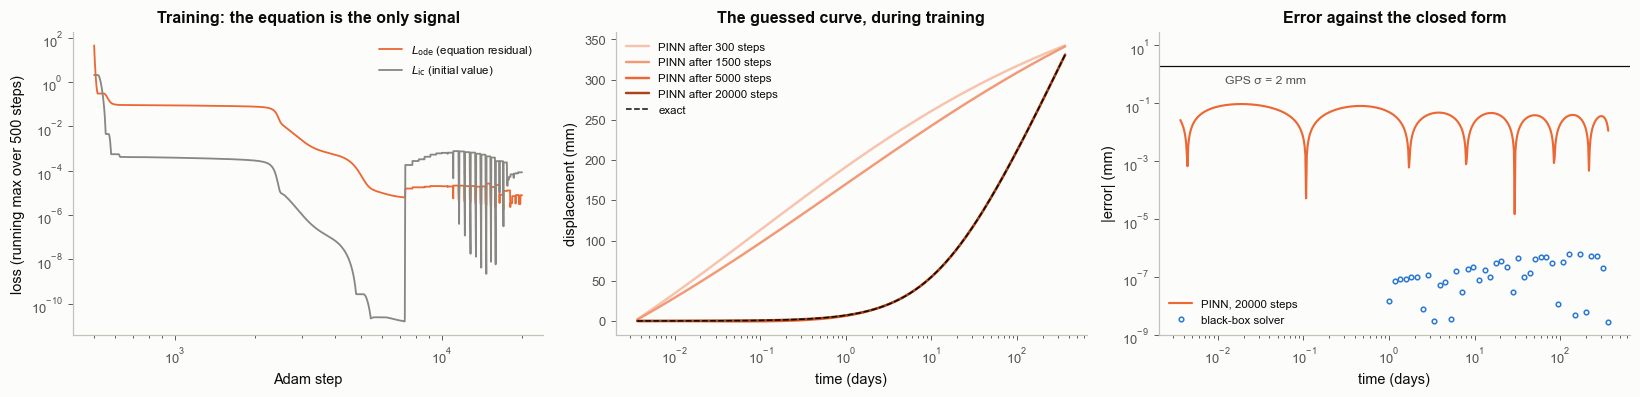

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.7))
it = np.arange(1, N_STEPS + 1)
runmax = lambda x, w=500: np.lib.stride_tricks.sliding_window_view(x, w).max(-1)   # envelope: L_ic flickers near zero
axs[0].plot(it[499:], runmax(Lode_hist), color=C_PINN, lw=1.2, label="$L_\\mathrm{ode}$ (equation residual)")
axs[0].plot(it[499:], runmax(Lic_hist), color=S.MUTED, lw=1.2, label="$L_\\mathrm{ic}$ (initial value)")
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("Adam step"); axs[0].set_ylabel("loss (running max over 500 steps)")
axs[0].set_title("Training: the equation is the only signal"); axs[0].legend(fontsize=7.5)
shades = ["#f7c3ad", "#f29a76", "#eb6834", "#a8431c"]
for end, c in zip(seg_ends, shades):
    axs[1].plot(tt * 365.25, 1e3 * snaps[end], color=c, lw=1.6, label=f"PINN after {end} steps")
axs[1].plot(tt * 365.25, 1e3 * u_tt, color=C_TRUE, lw=1.0, ls="--", label="exact")
axs[1].set_xscale("log"); axs[1].set_xlabel("time (days)"); axs[1].set_ylabel("displacement (mm)")
axs[1].set_title("The guessed curve, during training"); axs[1].legend(fontsize=7.5, loc="upper left")
axs[2].plot(tt * 365.25, 1e3 * err_fwd, color=C_PINN, lw=1.4, label=f"PINN, {N_STEPS} steps")
axs[2].plot(A.T_OBS * 365.25, 1e3 * np.abs(np.asarray(u_box) - np.asarray(u_ref)) + 1e-9, "o", ms=3, mfc="none",
            color=C_NUTS, label="black-box solver")
axs[2].axhline(1e3 * SIG, color=C_TRUE, lw=0.8); axs[2].text(1.2e-2, 1e3 * SIG * 0.25, "GPS σ = 2 mm", fontsize=8, color=S.INK2)
axs[2].set_xscale("log"); axs[2].set_yscale("log"); axs[2].set_ylim(1e-9, 30)
axs[2].set_xlabel("time (days)"); axs[2].set_ylabel("|error| (mm)"); axs[2].set_title("Error against the closed form")
axs[2].legend(fontsize=7.5, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "3-04_forward_pinn")
plt.show()

**How to read it.** Left: both loss terms fall by orders of magnitude, but not smoothly; the long plateaus are where
the network is rearranging itself (drawn as the running maximum over 500 steps, because the initial-value term
flickers near zero). Middle: early in training the network's curve is a smooth ramp that already ends near the right
value at one year but rises far too early; between 1,500 and 5,000 steps it snaps onto the exact curve (errors
printed above). Right: the final PINN error stays well below the
GPS noise (values printed above), but it is several orders of magnitude larger than the black-box solver's error,
and the PINN took far longer (ratio printed above) to produce this one curve.

**Common misreadings.**
* "A PINN is a faster solver." For one forward run of an ODE with a good solver, it is much slower and less accurate
  (printed above). Its appeal lies elsewhere (section 8).
* "The loss measures the error." The loss measures how badly the equation is violated *at the collocation points*.
  Section 3 shows a case where the loss is small and the curve is wrong.

## 3. Failure 1: stiffness and the time coordinate

**In plain words.** If afterslip starts very fast, most of the motion happens in the first hours or days. A network
that reads time on a linear axis, checked at evenly spaced times, has only a few checkpoints inside that burst. It can
satisfy the equation everywhere it is checked and still miss the burst.

**Precisely.** A problem is *stiff* when it contains time scales much shorter than the interval of interest; here the
ratio is (one year)/$t_c$. We change one knob, $\Delta\tau$ from 2.0 to 4.5 MPa, which shortens $t_c$ (printed), and
train the same network for the same number of steps with the same number of collocation points, once on log time and
once on linear time ($t\in[0, 1]$ yr, residual $t_c\,dy/dt - (e^{-y}-e^{y-2R})$, so both residuals are dimensionless).
All twelve trainings run in parallel with `jax.vmap`.

In [7]:
DTAUS = np.array([2.0, 2.5, 3.0, 3.5, 4.0, 4.5])
LN_TC = np.log(a_s / (K * v0)) - DTAUS / a_s
RS = DTAUS / a_s
print("t_c (days):", np.round(365.25 * np.exp(LN_TC), 2), "| collocation spacing on linear time:", f"{365.25 / 127:.2f} days")
t_day = np.geomspace(1 / 365.25, 1.0, 400)
t0 = time.time()
sweep = {}
for name, lossf, yf, tin in [("log", loss_log, y_log, jnp.log(jnp.asarray(t_day))), ("linear", loss_lin, y_lin, jnp.asarray(t_day))]:
    train = jax.jit(jax.vmap(lambda a, b: adam(lambda p: lossf(p, a, b), p0, N_STEPS, lr_fwd)[::2]))
    P_, H_ = train(jnp.asarray(LN_TC), jnp.asarray(RS))
    U = np.stack([G * a_s / K * np.asarray(jax.vmap(lambda x: yf(jax.tree_util.tree_map(lambda q: q[j], P_), x))(tin))
                  for j in range(len(DTAUS))])
    sweep[name] = dict(P=P_, U=U, L=np.asarray(H_[0])[:, -1])
T_SWEEP = time.time() - t0
U_EX = np.stack([np.asarray(u_exact(jnp.array([TRUE[0], TRUE[1], dt]), jnp.asarray(t_day))) for dt in DTAUS])
print(f"12 trainings in {T_SWEEP:.0f} s")
E_MAX = {n: np.array([np.abs(sweep[n]["U"][j] - U_EX[j]).max() for j in range(len(DTAUS))]) for n in sweep}
print(f"{'dtau':>5} {'t_c (d)':>8} | {'log time: max err':>18} {'final loss':>10} | {'linear time: max err':>21} {'final loss':>10} | u(1 yr)")
for j, dt in enumerate(DTAUS):
    e_log = np.abs(sweep["log"]["U"][j] - U_EX[j]); e_lin = np.abs(sweep["linear"]["U"][j] - U_EX[j])
    print(f"{dt:5.1f} {365.25 * np.exp(LN_TC[j]):8.2f} | {1e3 * e_log.max():15.3f} mm {sweep['log']['L'][j]:10.1e} | "
          f"{1e3 * e_lin.max():18.3f} mm {sweep['linear']['L'][j]:10.1e} | {1e3 * U_EX[j, -1]:.0f} mm")
print(f"stiffest case: final loss linear / log = {sweep['linear']['L'][-1] / sweep['log']['L'][-1]:.1f}, "
      f"largest error linear / log = {E_MAX['linear'][-1] / E_MAX['log'][-1]:.0f}")
print(f"linear-time PINN, stiffest case: largest displacement {1e3 * sweep['linear']['U'][-1].max():.0f} mm "
      f"(exact {1e3 * U_EX[-1].max():.0f} mm)")

t_c (days): [37.17 13.67  5.03  1.85  0.68  0.25] | collocation spacing on linear time: 2.88 days


12 trainings in 32 s
 dtau  t_c (d) |  log time: max err final loss |  linear time: max err final loss | u(1 yr)
  2.0    37.17 |           0.014 mm    3.5e-08 |              0.027 mm    1.5e-07 | 237 mm
  2.5    13.67 |           0.051 mm    6.7e-07 |              0.198 mm    1.5e-06 | 331 mm
  3.0     5.03 |           0.083 mm    1.8e-06 |              2.013 mm    2.8e-05 | 429 mm
  3.5     1.85 |           0.153 mm    2.1e-06 |             19.163 mm    7.8e-04 | 528 mm
  4.0     0.68 |           0.304 mm    1.9e-05 |            226.404 mm    4.9e-03 | 628 mm
  4.5     0.25 |           2.608 mm    1.9e-03 |            721.211 mm    6.5e-03 | 728 mm
stiffest case: final loss linear / log = 3.4, largest error linear / log = 276
linear-time PINN, stiffest case: largest displacement 1285 mm (exact 728 mm)


saved figures/3-04_time_coordinate.png


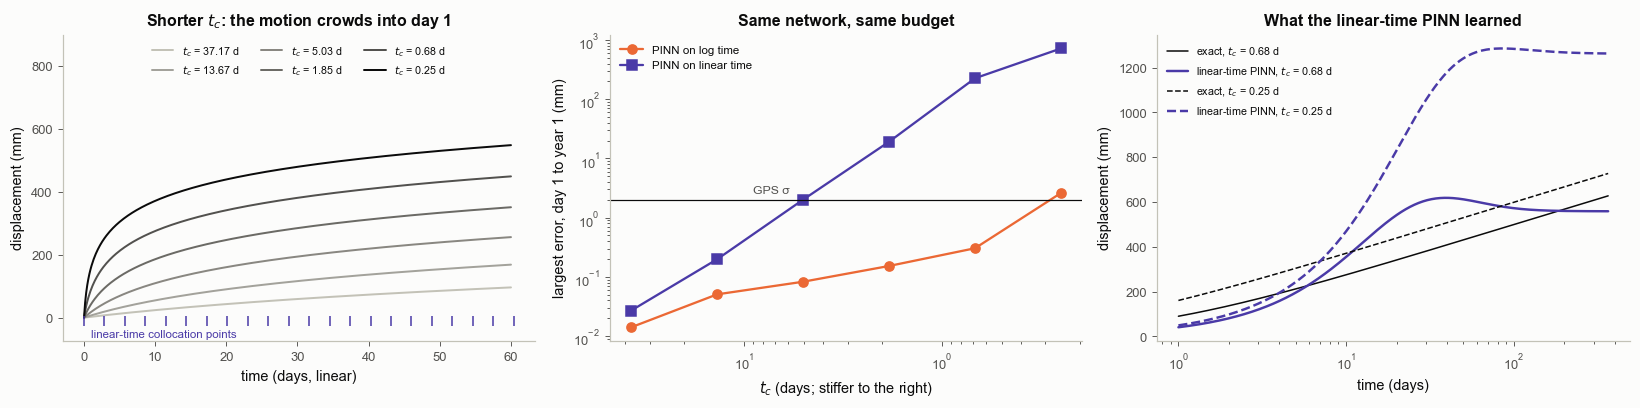

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
greys = ["#c3c2b7", "#a3a29b", "#898781", "#6b6a65", "#52514e", "#0b0b0b"]
tl = np.linspace(0, 60 / 365.25, 400)
for j, dt in enumerate(DTAUS):
    axs[0].plot(tl * 365.25, 1e3 * np.asarray(u_exact(jnp.array([TRUE[0], TRUE[1], dt]), jnp.asarray(tl))), color=greys[j], lw=1.3,
                label=f"$t_c$ = {365.25 * np.exp(LN_TC[j]):.2f} d")
axs[0].plot(np.asarray(T_C)[:22] * 365.25, np.zeros(22) - 12, "|", color=C_LIN, ms=6)
axs[0].text(1, -62, "linear-time collocation points", color=C_LIN, fontsize=7.5)
axs[0].set_ylim(-75, 900); axs[0].set_xlabel("time (days, linear)"); axs[0].set_ylabel("displacement (mm)")
axs[0].set_title("Shorter $t_c$: the motion crowds into day 1"); axs[0].legend(fontsize=7, loc="upper center", ncol=3)
tcd = 365.25 * np.exp(LN_TC)
for name, c, mk in [("log", C_PINN, "o"), ("linear", C_LIN, "s")]:
    err = [1e3 * np.abs(sweep[name]["U"][j] - U_EX[j]).max() for j in range(len(DTAUS))]
    axs[1].plot(tcd, err, mk + "-", color=c, label=f"PINN on {name} time")
axs[1].axhline(1e3 * SIG, color=C_TRUE, lw=0.8); axs[1].text(9, 1e3 * SIG * 1.3, "GPS σ", fontsize=8, color=S.INK2)
axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].invert_xaxis()
axs[1].set_xlabel("$t_c$ (days; stiffer to the right)"); axs[1].set_ylabel("largest error, day 1 to year 1 (mm)")
axs[1].set_title("Same network, same budget"); axs[1].legend(fontsize=7.5, loc="upper left")
for j, ls in zip([4, 5], ["-", "--"]):
    axs[2].plot(t_day * 365.25, 1e3 * U_EX[j], color=C_TRUE, lw=1.0, ls=ls, label=f"exact, $t_c$ = {tcd[j]:.2f} d")
    axs[2].plot(t_day * 365.25, 1e3 * sweep["linear"]["U"][j], color=C_LIN, lw=1.6, ls=ls, label=f"linear-time PINN, $t_c$ = {tcd[j]:.2f} d")
axs[2].set_xscale("log"); axs[2].set_xlabel("time (days)"); axs[2].set_ylabel("displacement (mm)")
axs[2].set_title("What the linear-time PINN learned"); axs[2].legend(fontsize=7, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "3-04_time_coordinate")
plt.show()

**How to read it.** Left: as $t_c$ shrinks the rise crowds into the first day, which falls between the first two
collocation points of the linear-time network (ticks). Middle: with the same network and budget, the log-time PINN
(orange) stays below the GPS noise except at the stiffest setting, while the linear-time PINN (violet) breaks down
once $t_c$ is shorter than the spacing of its collocation points (both printed above). Right: for the two stiffest
cases the linear-time network learned a different curve: too low in the first days, then far above the exact one,
then flat. The equation is checked only at the collocation points, and between them the network is free. The loss
alone does not reveal this: at the stiffest setting the two networks' final losses differ by a much smaller factor
than their errors (both ratios printed above).

**The image to keep.** Choose the coordinates so that the solution is smooth in them. The log-time variable is to a
PINN what adaptive step-size control is to a solver: it puts the effort where the solution changes.

**Common misreadings.**
* "More training would fix it." The table above compares equal budgets; whether a longer run helps depends on whether
  the collocation points can see the burst at all.

## 4. Failure 2: spectral bias

**In plain words.** A network trained by gradient descent learns the slowly varying parts of a function first and the
fast wiggles last. That is a property of the training, not of what the network can represent.

**Precisely.** We fit a network (3 hidden layers of 64, Adam, learning rate $10^{-3}$) by least squares to
$f(x) = \sin\pi x + 0.5\sin 8\pi x$ on 256 points and track, during training, the relative error of the two Fourier
modes of the fit (a curve written as a sum of sine waves of different frequencies; mode $k$ is the wave with $k$ half
periods over the range): $|\hat r_k| / |\hat f_k|$ for $k$ = 1 and 8, where $r$ is the residual. The effect is usually
called spectral bias (Rahaman et al. 2019, cited for the idea only). Then we measure how "high-frequency" the
afterslip curve is in each time coordinate: the number of Chebyshev terms (Chebyshev polynomials are a standard set of
polynomial building blocks on [−1, 1]; the more terms a curve needs, the more fine detail it has) needed to represent
it to 2 mm.

In [9]:
x_toy = jnp.linspace(-1, 1, 256, endpoint=False)
f_toy = jnp.sin(np.pi * x_toy) + 0.5 * jnp.sin(8 * np.pi * x_toy)
loss_toy = lambda p: (lambda yp: (jnp.mean((yp - f_toy) ** 2), yp))(jax.vmap(lambda x: mlp(p, x))(x_toy))
_, _, (L_toy, Y_toy) = jax.jit(lambda p: adam(loss_toy, p, 6000, lambda i: 1e-3))(init_mlp(jax.random.PRNGKey(0), [1, 64, 64, 64, 1]))
Y_toy = np.asarray(Y_toy)
F_res = np.abs(np.fft.rfft(Y_toy - np.asarray(f_toy)[None], axis=1)); F_f = np.abs(np.fft.rfft(np.asarray(f_toy)))
rel1, rel8 = F_res[:, 1] / F_f[1], F_res[:, 8] / F_f[8]
for it_ in [100, 300, 1000, 2000, 4000, 6000]:
    print(f"step {it_:5d}: relative error of mode 1 {rel1[it_ - 1]:.3f}, of mode 8 {rel8[it_ - 1]:.3f}")
first = lambda r: int(np.argmax(r < 0.1)) + 1
print(f"first step with relative error < 0.1: mode 1 at {first(rel1)}, mode 8 at {first(rel8)}")

# Chebyshev content of the afterslip curve (t_c = 1.85 days) on linear and on log time, both mapped to [-1, 1]
from numpy.polynomial import chebyshev as C
th_st = np.array([TRUE[0], TRUE[1], 3.5])
f_lin = lambda x: np.asarray(u_exact(jnp.asarray(th_st), jnp.asarray((x + 1) / 2)))
f_log = lambda x: np.asarray(u_exact(jnp.asarray(th_st), jnp.exp(XI0 + (x + 1) / 2 * (XI1 - XI0))))
xx = np.cos(np.linspace(0, np.pi, 4001))
cheb = {}
for name, fn in [("linear", f_lin), ("log", f_log)]:
    c = C.chebinterpolate(fn, 600)
    need = next(n for n in range(1, 601) if np.abs(C.chebval(xx, c[:n]) - fn(xx)).max() < SIG)
    cheb[name] = (np.abs(c), need)
    print(f"{name:6s} time: Chebyshev terms needed for a 2 mm fit: {need}")

step   100: relative error of mode 1 0.383, of mode 8 1.134
step   300: relative error of mode 1 0.025, of mode 8 1.006
step  1000: relative error of mode 1 0.007, of mode 8 0.964
step  2000: relative error of mode 1 0.002, of mode 8 0.953
step  4000: relative error of mode 1 0.000, of mode 8 0.609
step  6000: relative error of mode 1 0.002, of mode 8 0.038
first step with relative error < 0.1: mode 1 at 153, mode 8 at 5184


linear time: Chebyshev terms needed for a 2 mm fit: 24
log    time: Chebyshev terms needed for a 2 mm fit: 7


saved figures/3-04_spectral_bias.png


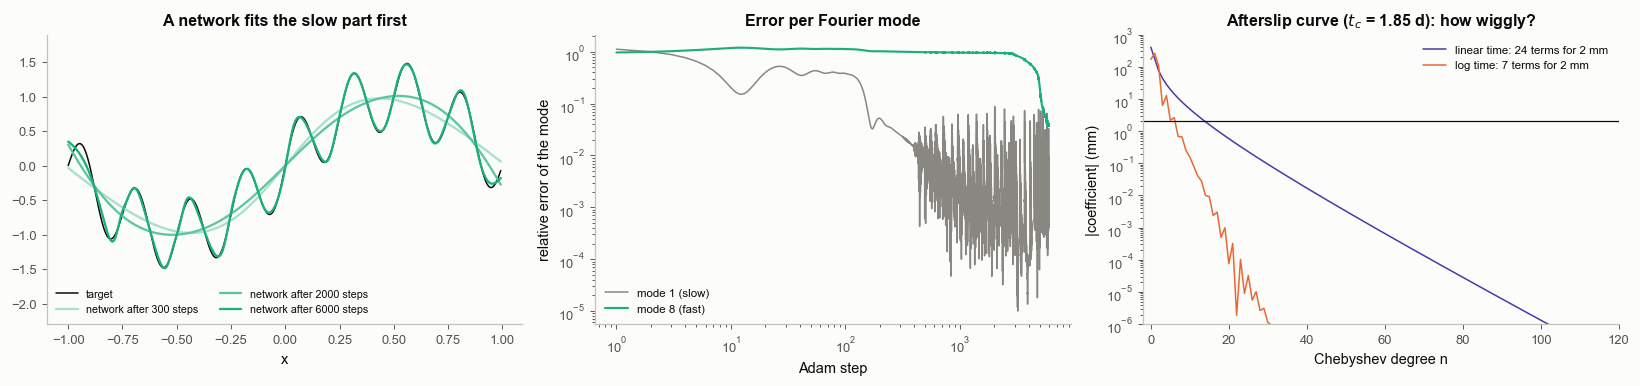

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
axs[0].plot(x_toy, f_toy, color=C_TRUE, lw=1.0, label="target")
for it_, c in zip([300, 2000, 6000], ["#a8e0c9", "#5cc69d", S.AQUA]):
    axs[0].plot(x_toy, Y_toy[it_ - 1], color=c, lw=1.5, label=f"network after {it_} steps")
axs[0].set_xlabel("x"); axs[0].set_title("A network fits the slow part first"); axs[0].legend(fontsize=7, loc="lower left", ncol=2)
axs[0].set_ylim(-2.3, 1.9)
st_ = np.arange(1, 6001)
axs[1].plot(st_, rel1, color=S.MUTED, lw=1.0, label="mode 1 (slow)"); axs[1].plot(st_, rel8, color=S.AQUA, lw=1.4, label="mode 8 (fast)")
axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].set_xlabel("Adam step"); axs[1].set_ylabel("relative error of the mode")
axs[1].set_title("Error per Fourier mode"); axs[1].legend(fontsize=7.5)
for name, c in [("linear", C_LIN), ("log", C_PINN)]:
    axs[2].plot(np.arange(len(cheb[name][0])), 1e3 * cheb[name][0] + 1e-12, color=c, lw=1.0,
                label=f"{name} time: {cheb[name][1]} terms for 2 mm")
axs[2].axhline(1e3 * SIG, color=C_TRUE, lw=0.8)
axs[2].set_yscale("log"); axs[2].set_ylim(1e-6, 1e3); axs[2].set_xlim(-2, 120); axs[2].set_xlabel("Chebyshev degree n"); axs[2].set_ylabel("|coefficient| (mm)")
axs[2].set_title("Afterslip curve ($t_c$ = 1.85 d): how wiggly?"); axs[2].legend(fontsize=7.5)
fig.tight_layout()
bk.savefig(fig, "3-04_spectral_bias")
plt.show()

**How to read it.** Left and middle: the slow mode is fitted within a few hundred steps, the fast mode only thousands
of steps later (first steps below 10 % printed above), although nothing in the network prevents fitting both at once.
Right: on linear time the afterslip curve has a sharp corner near $t = 0$ and needs many Chebyshev terms to reach
2 mm; on log time it needs several times fewer (both printed; the horizontal line marks 2 mm for a single
coefficient, while the counts are where the whole remaining tail of the series falls below 2 mm). A PINN on linear time is asking gradient descent for
exactly the high-frequency detail it learns last. This is a likely second reason why the log-time PINN of section 3
works, besides where the collocation points sit; the experiment there changes both at once and does not separate them.

**Common misreadings.**
* "Spectral bias means networks cannot represent sharp features." They can; gradient descent reaches them late.
  Remedies change the input (log time here; in general "Fourier features", sines and cosines of the input at several
  frequencies, fed to the network) or the weighting of the loss.

## 5. The inverse PINN: friction from GPS

**In plain words.** Now the friction parameters are unknown. We let them be trainable numbers next to the network
weights and add a third term: the network's curve must pass close to the GPS data. The data pull the curve; the
physics term ties the curve to the parameters; the parameters move until both agree.

**Precisely.** Unknowns $\theta = (\ln a\sigma, \ln v_0)$ with $\Delta\tau$ = 2.5 MPa known, and the network $s_w(\xi)$
(slip in metres, $s_w = 0.5\,\mathrm{m}\times$ network output). All three loss terms are written in the same unit,
surface displacement divided by the GPS noise σ:
$$L(w,\theta) = \underbrace{\frac{1}{N_c}\sum_j \Big(\frac{g\,r_{w,\theta}(\xi_j)}{\sigma}\Big)^2}_{L_\text{ode}}
 + \underbrace{\Big(\frac{g\,s_w(\xi_0)}{\sigma}\Big)^2}_{L_\text{ic}}
 + w_d\,\underbrace{\frac{1}{N_d}\sum_i\Big(\frac{g\,s_w(\ln t_i) - d_i}{\sigma}\Big)^2}_{L_\text{data}},\qquad
r_{w,\theta}(\xi) = \frac{ds_w}{d\xi} - t\,2v_0\sinh\frac{\Delta\tau - k s_w}{a\sigma}.$$
$L_\text{data}$ is $\chi^2/N$. The data weight $w_d$ is a choice (section 6); here $w_d = 1$. Fukushima et al. (2026,
p. 16) give the probabilistic reading: "This loss function can be seen as the maximum likelihood estimation, and
weight $w_\text{ini}$ and $w_\text{data}$ can be written as $w_\text{ini} = \sigma_\text{ode}^2/\sigma_\text{ini}^2$
and $w_\text{data} = \sigma_\text{ode}^2/\sigma_\text{data}^2$". In that reading, $w_d = 1$ says the equation may be
violated by about one σ of surface motion per e-fold of time.

**The classical answer** to grade against: the exact posterior on a grid (flat prior on the box of
`A.SP_BOUNDS`, likelihood from the closed form), and NumPyro NUTS (2.18) with the black-box solver inside the
likelihood (gradients through diffrax; 2 chains, dense mass matrix, 2.18; R-hat and ESS, 2.19).

In [11]:
d_clean = np.asarray(u_box)
d_obs = d_clean + SIG * np.random.default_rng(1).standard_normal(len(A.T_OBS))
DTAU_KNOWN, S0 = 2.5, 0.5
XI_D = jnp.log(t_obs)
s_net = lambda p, xi: S0 * mlp(p, to_unit(xi))


def inv_losses(P_, d):
    net, (la, lv) = P_["net"], P_["theta"]
    a_s_, v0_ = jnp.exp(la), jnp.exp(lv)

    def r(xi):
        return jax.grad(s_net, argnums=1)(net, xi) - jnp.exp(xi) * 2 * v0_ * jnp.sinh((DTAU_KNOWN - K * s_net(net, xi)) / a_s_)
    L_ode = jnp.mean((G * jax.vmap(r)(XI_C) / SIG) ** 2)
    L_ic = (G * s_net(net, XI0) / SIG) ** 2
    L_data = jnp.mean(((G * jax.vmap(lambda x: s_net(net, x))(XI_D) - d) / SIG) ** 2)
    return L_ode, L_ic, L_data


def train_inverse(w_d, seed, theta0, d, n=N_STEPS):
    def loss(P_):
        L_ode, L_ic, L_data = inv_losses(P_, d)
        return L_ode + L_ic + w_d * L_data, (L_ode, L_data, P_["theta"])
    P0 = {"net": init_mlp(jax.random.PRNGKey(seed), SIZES), "theta": theta0}
    P_, _, (L, (L_ode, L_data, th_path)) = adam(loss, P0, n, lambda i: 3e-3 * 0.1 ** (i / n))
    return P_["theta"], L_ode[-1], L_data[-1], th_path[::10], L[-1]


train_many = jax.jit(jax.vmap(train_inverse, in_axes=(0, 0, 0, None)))

# seeds 0-3 from one starting guess (A), and three other starting guesses (B, C, D) with seed 0
STARTS = {"A": (1.0, 0.003), "B": (0.25, 0.3), "C": (1.5, 0.1), "D": (0.3, 0.002)}
cfg = [("A", s) for s in range(4)] + [(k, 0) for k in "BCD"]
th0s = jnp.asarray([[np.log(STARTS[k][0]), np.log(STARTS[k][1])] for k, _ in cfg])
t0 = time.time()
th_hat, Lode_f, Ldat_f, paths, _ = train_many(jnp.ones(len(cfg)), jnp.asarray([s for _, s in cfg]), th0s, jnp.asarray(d_obs))
jax.block_until_ready(th_hat)
T_INV = time.time() - t0
th_hat, paths = np.asarray(th_hat), np.asarray(paths)
print(f"{len(cfg)} inverse PINNs ({N_STEPS} steps each) in {T_INV:.0f} s, run in parallel")
for j, (k, s) in enumerate(cfg):
    a0, v00 = STARTS[k]
    tc0 = a0 / (K * v00 * np.exp(DTAU_KNOWN / a0)) * 365.25
    print(f"start {k} (a_sigma {a0}, v0 {v00}; t_c {tc0:.1e} d), seed {s}: ln a_sigma {th_hat[j, 0]:.4f}, ln v0 {th_hat[j, 1]:.4f} | "
          f"L_ode {float(Lode_f[j]):.1e}, chi2/N {float(Ldat_f[j]):.3f}")
print(f"true: ln a_sigma {TRUE[0]:.4f}, ln v0 {TRUE[1]:.4f}")

7 inverse PINNs (20000 steps each) in 18 s, run in parallel
start A (a_sigma 1.0, v0 0.003; t_c 3.3e+03 d), seed 0: ln a_sigma -0.6901, ln v0 -3.4975 | L_ode 1.4e-02, chi2/N 0.834
start A (a_sigma 1.0, v0 0.003; t_c 3.3e+03 d), seed 1: ln a_sigma -0.6895, ln v0 -3.4954 | L_ode 8.7e-03, chi2/N 0.830
start A (a_sigma 1.0, v0 0.003; t_c 3.3e+03 d), seed 2: ln a_sigma -0.6893, ln v0 -3.4947 | L_ode 1.5e-02, chi2/N 0.842
start A (a_sigma 1.0, v0 0.003; t_c 3.3e+03 d), seed 3: ln a_sigma -0.6899, ln v0 -3.4969 | L_ode 4.4e-02, chi2/N 0.884
start B (a_sigma 0.25, v0 0.3; t_c 4.6e-03 d), seed 0: ln a_sigma -1.3610, ln v0 -1.2315 | L_ode 1.8e+03, chi2/N 14828.283
start C (a_sigma 1.5, v0 0.1; t_c 3.4e+02 d), seed 0: ln a_sigma -0.6901, ln v0 -3.4976 | L_ode 1.6e-02, chi2/N 0.835
start D (a_sigma 0.3, v0 0.002; t_c 4.4e+00 d), seed 0: ln a_sigma -0.8047, ln v0 -3.9220 | L_ode 1.1e+00, chi2/N 2.022
true: ln a_sigma -0.6931, ln v0 -3.5066


In [12]:
# exact posterior on a grid (closed form), zoomed on the data's answer
def posterior_grid(d, ca, cv, half_a=0.06, half_v=0.22, n=241):
    xa = np.linspace(ca - half_a, ca + half_a, n); yv = np.linspace(cv - half_v, cv + half_v, n)
    X, Y = np.meshgrid(xa, yv)
    U = np.asarray(jax.jit(jax.vmap(lambda a, v: u_exact(jnp.stack([a, v, DTAU_KNOWN]), t_obs)))(jnp.asarray(X.ravel()), jnp.asarray(Y.ravel())))
    logL = (-0.5 * np.sum((U - d) ** 2, 1) / SIG ** 2).reshape(X.shape)
    Pp = np.exp(logL - logL.max()); dx, dy = xa[1] - xa[0], yv[1] - yv[0]; Pp /= Pp.sum() * dx * dy
    return P.Grid(X, Y, Pp, dx, dy, P.hdr_levels(Pp))


g_post = posterior_grid(d_obs, TRUE[0], TRUE[1])
mu_post, cov_post = g_post.mean, g_post.cov
sd_post = np.sqrt(np.diag(cov_post))
edge = g_post.P[0].sum() + g_post.P[-1].sum() + g_post.P[:, 0].sum() + g_post.P[:, -1].sum()
print(f"exact posterior (grid): ln a_sigma {mu_post[0]:.4f} ± {sd_post[0]:.4f}, ln v0 {mu_post[1]:.4f} ± {sd_post[1]:.4f}, "
      f"correlation {cov_post[0, 1] / sd_post.prod():.3f} (probability on the grid edge {edge * g_post.dx * g_post.dy:.1e})")


def model(d):
    la = numpyro.sample("ln_asigma", dist.Uniform(*A.SP_BOUNDS[0]))
    lv = numpyro.sample("ln_v0", dist.Uniform(*A.SP_BOUNDS[1]))
    u = A.single_patch_series(jnp.stack([la, lv, DTAU_KNOWN]), t_obs, rtol=1e-6, atol=1e-9)
    numpyro.sample("d", dist.Normal(u, SIG), obs=d)


th_t = jnp.asarray(TRUE)
print(f"black box at rtol 1e-6 vs closed form: {1e3 * float(jnp.max(jnp.abs(A.single_patch_series(th_t, t_obs, rtol=1e-6, atol=1e-9) - u_exact(th_t, t_obs)))):.1e} mm")
t0 = time.time()
mc = MCMC(NUTS(model, dense_mass=True, init_strategy=init_to_uniform(radius=0.5)), num_warmup=200, num_samples=300,
          num_chains=2, chain_method="vectorized", progress_bar=False)
mc.run(jax.random.PRNGKey(0), d=jnp.asarray(d_obs), extra_fields=("num_steps",))
T_NUTS = time.time() - t0
nuts = mc.get_samples(group_by_chain=True)
n_grad = int(np.sum(np.asarray(mc.get_extra_fields()["num_steps"])))
print(f"NUTS through diffrax: {T_NUTS:.0f} s, 2 chains x 300 draws after 200 warm-up, {n_grad} gradient evaluations (sampling phase)")
for k_, j in [("ln_asigma", 0), ("ln_v0", 1)]:
    x = np.asarray(nuts[k_])
    print(f"   {k_:9s}: {x.mean():.4f} ± {x.std():.4f} (grid {mu_post[j]:.4f} ± {sd_post[j]:.4f}); "
          f"mean off by {(x.mean() - mu_post[j]) / sd_post[j]:+.2f} sd; split R-hat {float(split_gelman_rubin(x)):.3f}, ESS {D.ess(x):.0f}")
seed_sd = th_hat[:4].std(0, ddof=1)
print(f"spread of the PINN answer over 4 network seeds (start A): {seed_sd[0]:.5f}, {seed_sd[1]:.5f} "
      f"= {seed_sd[0] / sd_post[0]:.2f} and {seed_sd[1] / sd_post[1]:.2f} posterior sd")
print(f"PINN (start A, seed 0) minus posterior mean, in posterior sd: {(th_hat[0, 0] - mu_post[0]) / sd_post[0]:+.2f}, "
      f"{(th_hat[0, 1] - mu_post[1]) / sd_post[1]:+.2f}")

exact posterior (grid): ln a_sigma -0.6901 ± 0.0077, ln v0 -3.4966 ± 0.0286, correlation 0.984 (probability on the grid edge 9.2e-14)


black box at rtol 1e-6 vs closed form: 2.5e-05 mm


NUTS through diffrax: 48 s, 2 chains x 300 draws after 200 warm-up, 5270 gradient evaluations (sampling phase)
   ln_asigma: -0.6895 ± 0.0074 (grid -0.6901 ± 0.0077); mean off by +0.08 sd; split R-hat 1.023, ESS 152
   ln_v0    : -3.4944 ± 0.0275 (grid -3.4966 ± 0.0286); mean off by +0.08 sd; split R-hat 1.023, ESS 157
spread of the PINN answer over 4 network seeds (start A): 0.00038, 0.00129 = 0.05 and 0.05 posterior sd
PINN (start A, seed 0) minus posterior mean, in posterior sd: +0.01, -0.03


saved figures/3-04_inverse.png


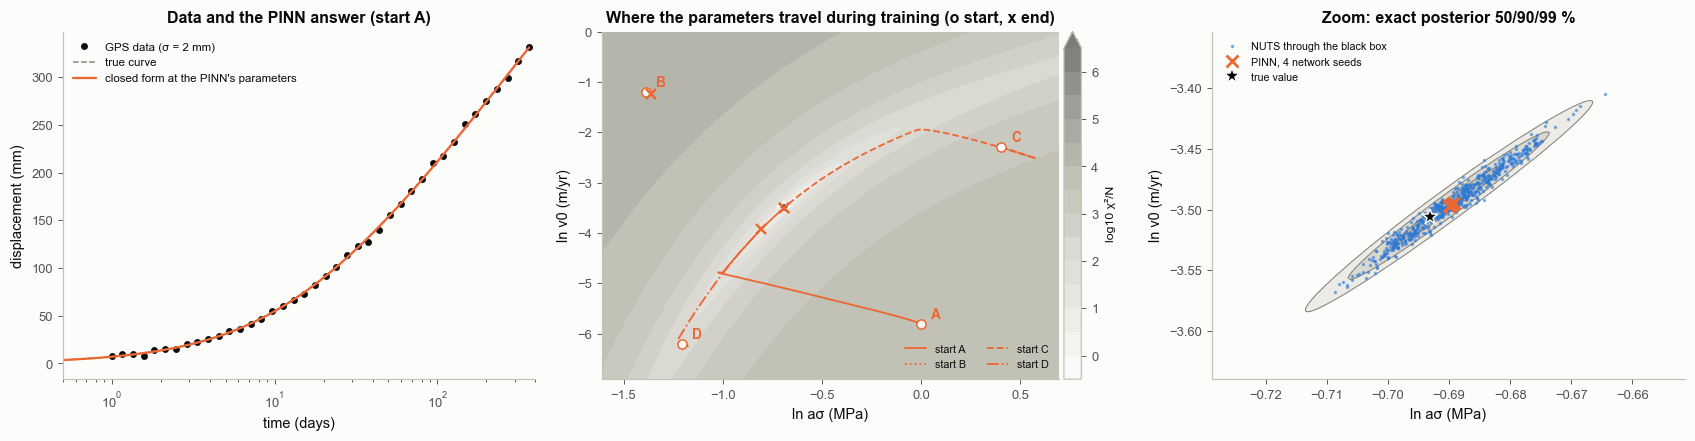

In [13]:
# the chi^2/N landscape over the whole prior box (closed form), for the wide view
la_w = np.linspace(*A.SP_BOUNDS[0], 161); lv_w = np.linspace(*A.SP_BOUNDS[1], 161)
XW, YW = np.meshgrid(la_w, lv_w)
UW = np.asarray(jax.jit(jax.vmap(lambda a, v: u_exact(jnp.stack([a, v, DTAU_KNOWN]), t_obs)))(jnp.asarray(XW.ravel()), jnp.asarray(YW.ravel())))
CHI = (np.mean(((UW - d_obs) / SIG) ** 2, 1)).reshape(XW.shape)

fig = plt.figure(figsize=(15.5, 4.1))
gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.15, 1.0])
ax = fig.add_subplot(gs[0])
ax.plot(A.T_OBS * 365.25, 1e3 * d_obs, "o", ms=3.5, color=C_TRUE, label="GPS data (σ = 2 mm)")
ax.plot(tt * 365.25, 1e3 * u_tt, color=S.MUTED, lw=1.0, ls="--", label="true curve")
u_at_hat = np.asarray(u_exact(jnp.array([th_hat[0, 0], th_hat[0, 1], DTAU_KNOWN]), jnp.asarray(tt)))
ax.plot(tt * 365.25, 1e3 * u_at_hat, color=C_PINN, lw=1.5, label="closed form at the PINN's parameters")
ax.set_xscale("log"); ax.set_xlim(0.5, 400); ax.set_xlabel("time (days)"); ax.set_ylabel("displacement (mm)")
ax.set_title("Data and the PINN answer (start A)"); ax.legend(fontsize=7.5, loc="upper left")
ax = fig.add_subplot(gs[1])
cs = ax.contourf(XW, YW, np.log10(CHI), levels=np.arange(-0.5, 6.6, 0.5), cmap=S.GREYS, extend="max")
cb = fig.colorbar(cs, ax=ax, pad=0.01); cb.set_label("log10 χ²/N", fontsize=8)
ax.plot(TRUE[0], TRUE[1], "*", color=C_TRUE, ms=9, mec=S.SURFACE, zorder=4)
LS = {"A": "-", "B": ":", "C": "--", "D": "-."}
for j, (k, s) in enumerate(cfg):
    if s > 0:
        continue
    ax.plot(paths[j, :, 0], paths[j, :, 1], color=C_PINN, lw=1.2, ls=LS[k], label=f"start {k}", zorder=5)
    ax.plot(paths[j, 0, 0], paths[j, 0, 1], "o", color=C_PINN, mfc=S.SURFACE, ms=6, zorder=6)
    ax.text(paths[j, 0, 0] + 0.05, paths[j, 0, 1] + 0.12, k, color=C_PINN, fontsize=9, fontweight="bold")
    ax.plot(paths[j, -1, 0], paths[j, -1, 1], "x", color=C_PINN, ms=7, mew=1.6, zorder=6)
ax.legend(fontsize=7, loc="lower right", ncol=2)
ax.set_xlabel("ln aσ (MPa)"); ax.set_ylabel("ln v0 (m/yr)")
ax.set_title("Where the parameters travel during training (o start, x end)")
ax = fig.add_subplot(gs[2])
BP.density(ax, g_post)
nx = np.asarray(nuts["ln_asigma"]).ravel(); ny = np.asarray(nuts["ln_v0"]).ravel()
ax.plot(nx, ny, ".", color=C_NUTS, ms=2.5, alpha=0.5, label="NUTS through the black box")
ax.plot(th_hat[:4, 0], th_hat[:4, 1], "x", color=C_PINN, ms=8, mew=1.8, label="PINN, 4 network seeds")
ax.plot(TRUE[0], TRUE[1], "*", color=C_TRUE, ms=11, mec=S.SURFACE, label="true value")
ax.set_xlim(mu_post[0] - 5 * sd_post[0], mu_post[0] + 5 * sd_post[0]); ax.set_ylim(mu_post[1] - 5 * sd_post[1], mu_post[1] + 5 * sd_post[1])
ax.set_xlabel("ln aσ (MPa)"); ax.set_ylabel("ln v0 (m/yr)")
ax.set_title("Zoom: exact posterior 50/90/99 %"); ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "3-04_inverse")
plt.show()

**How to read it.** Left: the GPS data and, in orange, the curve that the *trusted* solver produces at the PINN's
parameters; re-solving at the estimate is the check that the PINN's answer is a physical answer and not just a curve
that fits. Middle: the parameters' journey over the χ²/N landscape of the whole prior box. The data allow only a thin
valley, because a larger $a\sigma$ can be traded against a larger $v_0$ (correlation printed above). The straight
diagonal legs are Adam's signature: early on it moves every parameter by about the learning rate per step. Two of the
starts reach the valley floor; the outcome of each start is printed above with its $t_c$. A start in the corner
where $t_c$ is tiny begins in the stiff regime of section 3 and does not recover; a start far down the valley is
still crawling along it when training stops. Right: the zoom. The four PINN answers (different network seeds) sit on
top of each other near the centre of the exact posterior (grey regions), where the NUTS samples are; their spread is
a small fraction of the posterior width (printed). The NUTS run is kept short to save time: its means and spreads
agree with the grid (offsets printed), while its split R-hat is slightly above the usual 1.01 threshold and its ESS
is modest, so on its own it would need longer chains before being trusted.

**The image to keep.** An inverse PINN is an optimiser. It returns one point near the best fit when it converges,
and the answer depends on where it starts.

**Common misreadings.**
* "The spread over network seeds is the uncertainty." It measures how reproducibly the optimiser converges, here a
  small fraction of the posterior width (printed above). Section 7 goes further.
* "A good optimiser finds the answer from anywhere." Starts B and D show otherwise. Fukushima et al. chose the output
  scaling of their parameter network from the known order of magnitude of the parameters: "This corresponds to setting
  the initial values near the true values" (2025, p. 6).

## 6. Failure 3: loss weights and the units of the residual

**In plain words.** The loss adds two kinds of misfit: misfit to the physics and misfit to the data. How they are
weighted against each other decides who wins. Weight the data too little and the network solves the equation for
whatever parameters it started with; weight them too much and the network bends away from the equation to chase the
noise. Worse, if the physics misfit is measured in units that the unknown parameters themselves rescale, the optimiser
can change a parameter just to make the physics misfit look smaller.

**Precisely.** (a) Sweep $w_d$ over eight orders of magnitude, two network seeds each, same data and start A. (The
left panel uses a "symlog" axis: logarithmic far from zero, linear near zero, so values of both signs fit.)
(b) The units trap: the same problem with the residual written in the dimensionless slip $y = ks/a\sigma$ of section 2,
$L = \overline{r_y^2} + y(\xi_0)^2 + w_d\,\chi^2/N$, with $w_d$ chosen so that this loss *equals* the one of
section 5 at the true $a\sigma$ (the factor $(g\,a\sigma/k\sigma)^2$ is printed). Away from the true $a\sigma$ the two
losses differ, because $u = g\,a\sigma\,y/k$: a larger $a\sigma$ makes an error in $y$ cost less in this loss.
For every run we also re-solve with the closed form at the estimated parameters and report that $\chi^2/N$.

In [14]:
W_SWEEP = [1e-4, 1e-2, 1e2, 1e4]
cfg_w = [(w, s) for w in W_SWEEP for s in (0, 1)]
t0 = time.time()
th_w, Lode_w, Ldat_w, _, Ltot_w = train_many(jnp.asarray([w for w, _ in cfg_w]), jnp.asarray([s for _, s in cfg_w]),
                                     jnp.tile(th0s[0], (len(cfg_w), 1)), jnp.asarray(d_obs))
th_w = np.asarray(th_w)
# add w_d = 1 (seeds 0 and 1 from section 5)
W_ALL = [1e-4, 1e-2, 1.0, 1e2, 1e4]
res_w = {}
for w in W_ALL:
    if w == 1.0:
        rows = [(th_hat[s], float(Lode_f[s]), float(Ldat_f[s])) for s in (0, 1)]
    else:
        rows = [(th_w[j], float(Lode_w[j]), float(Ldat_w[j])) for j, (ww, s) in enumerate(cfg_w) if ww == w]
    res_w[w] = rows
chi_resolve = lambda th: float(np.mean(((np.asarray(u_exact(jnp.array([th[0], th[1], DTAU_KNOWN]), t_obs)) - d_obs) / SIG) ** 2))
print(f"8 more inverse PINNs in {time.time() - t0:.0f} s")
print(f"{'w_d':>7} {'seed':>4} | {'ln a_sigma':>10} {'(sd units)':>10} {'ln v0':>8} {'(sd units)':>10} | {'L_ode':>8} {'PINN chi2/N':>11} {'re-solved chi2/N':>16}")
for w in W_ALL:
    for s, (th, lo, ld) in enumerate(res_w[w]):
        z = (th - mu_post) / sd_post
        print(f"{w:7.0e} {s:4d} | {th[0]:10.4f} {z[0]:+10.1f} {th[1]:8.4f} {z[1]:+10.1f} | {lo:8.1e} {ld:11.3f} {chi_resolve(th):16.3f}")
chi_true = chi_resolve(TRUE[:2])
print(f"for reference: chi2/N of the true parameters {chi_true:.3f}, of the posterior mean {chi_resolve(mu_post):.3f}")

# is the small-weight answer what the loss wants, or where the optimiser stopped?
def train_trace(w_d, theta0, d, freeze, n=N_STEPS):
    """One inverse PINN with its history; freeze=True keeps theta fixed and trains only the network."""
    def loss(P_):
        Q = {"net": P_["net"], "theta": jax.lax.stop_gradient(P_["theta"]) if freeze else P_["theta"]}
        L_ode, L_ic, L_data = inv_losses(Q, d)
        return L_ode + L_ic + w_d * L_data, (L_ode, L_data, P_["theta"])
    P0 = {"net": init_mlp(jax.random.PRNGKey(0), SIZES), "theta": theta0}
    _, _, (L, (L_ode, L_data, th)) = adam(loss, P0, n, lambda i: 3e-3 * 0.1 ** (i / n))
    return L, L_ode, L_data, th


tr = {k: [np.asarray(x) for x in jax.jit(lambda f=f: train_trace(1e-4, jnp.asarray(mu_post), jnp.asarray(d_obs), f))()]
      for k, f in [("frozen", True), ("free", False)]}
L_A = float(Ltot_w[cfg_w.index((1e-4, 0))])                               # start A, seed 0: total loss
print(f"w_d = 1e-4, final loss: theta frozen at the posterior mean {tr['frozen'][0][-1]:.1e} | "
      f"theta free, started at the posterior mean {tr['free'][0][-1]:.1e} | theta free, start A {L_A:.1e}")
for i in [2000, 5000, N_STEPS - 1]:
    z_ = (tr["free"][3][i] - mu_post) / sd_post
    print(f"   free run from the posterior mean, step {i + 1:5d}: offset {z_[0]:+6.1f}, {z_[1]:+6.1f} sd | "
          f"L_ode {tr['free'][1][i]:.2e}, chi2/N {tr['free'][2][i]:.1f}")

# (b) the units trap
fac = G * a_s / (K * SIG)
y_net_ = lambda p, xi: mlp(p, to_unit(xi))


def trap_loss(P_, w_d, d):
    net, (la, lv) = P_["net"], P_["theta"]
    a_s_ = jnp.exp(la); R_ = DTAU_KNOWN / a_s_; ln_tc_ = la - jnp.log(K) - lv - R_

    def r(xi):
        y = y_net_(net, xi)
        return jax.grad(y_net_, argnums=1)(net, xi) - jnp.exp(xi - ln_tc_ - y) + jnp.exp(xi - ln_tc_ + y - 2 * R_)
    L_ode = jnp.mean(jax.vmap(r)(XI_C) ** 2)
    L_data = jnp.mean(((G * a_s_ / K * jax.vmap(lambda x: y_net_(net, x))(XI_D) - d) / SIG) ** 2)
    return L_ode + y_net_(net, XI0) ** 2 + w_d * L_data, (L_ode, L_data, P_["theta"])


P_trap, _, (_, (Lode_trap, Ldat_trap, path_trap)) = jax.jit(lambda: adam(
    lambda q: trap_loss(q, 1 / fac ** 2, jnp.asarray(d_obs)), {"net": init_mlp(jax.random.PRNGKey(0), SIZES), "theta": th0s[0]},
    N_STEPS, lambda i: 3e-3 * 0.1 ** (i / N_STEPS)))()
th_trap = np.asarray(P_trap["theta"])
print(f"\nunits trap: factor (g a_sigma / k sigma)^2 at the true a_sigma = {fac ** 2:.0f}, so w_d = 1/{fac ** 2:.0f}")
print(f"   estimate a_sigma = {np.exp(th_trap[0]):.2f} MPa (true {a_s}), v0 = {np.exp(th_trap[1]):.3f} m/yr (true {v0}); "
      f"PINN chi2/N {float(Ldat_trap[-1]):.3f}; re-solved chi2/N {chi_resolve(th_trap):.0f}")
u_trap_net = G * np.exp(th_trap[0]) / K * np.asarray(jax.vmap(lambda x: y_net_(P_trap["net"], x))(jnp.log(jnp.asarray(tt))))
u_trap_phys = np.asarray(u_exact(jnp.array([th_trap[0], th_trap[1], DTAU_KNOWN]), jnp.asarray(tt)))

8 more inverse PINNs in 19 s
    w_d seed | ln a_sigma (sd units)    ln v0 (sd units) |    L_ode PINN chi2/N re-solved chi2/N
  1e-04    0 |     1.0784     +228.6  -7.4516     -138.4 |  4.3e-03    5982.557         6059.737
  1e-04    1 |     0.8274     +196.2  -7.0082     -122.9 |  5.0e-03    5966.194         6042.615
  1e-02    0 |    -1.0819      -50.6  -5.3246      -64.0 |  8.2e-02      70.512           75.074
  1e-02    1 |    -1.0468      -46.1  -5.1273      -57.1 |  5.4e-02      58.049           61.942
  1e+00    0 |    -0.6901       +0.0  -3.4975       -0.0 |  1.4e-02       0.834            0.862
  1e+00    1 |    -0.6895       +0.1  -3.4954       +0.0 |  8.7e-03       0.830            0.862
  1e+02    0 |    -0.7009       -1.4  -3.5365       -1.4 |  3.5e-01       0.803            0.909
  1e+02    1 |    -0.7013       -1.4  -3.5379       -1.4 |  3.0e-01       0.804            0.913
  1e+04    0 |    -0.7006       -1.3  -3.5370       -1.4 |  3.3e+00       0.802            0.911
 

w_d = 1e-4, final loss: theta frozen at the posterior mean 7.1e-03 | theta free, started at the posterior mean 2.8e-01 | theta free, start A 6.0e-01
   free run from the posterior mean, step  2001: offset   +4.5,   -2.4 sd | L_ode 1.80e+02, chi2/N 5127.5
   free run from the posterior mean, step  5001: offset   +1.5,   -3.7 sd | L_ode 7.68e+00, chi2/N 32.7
   free run from the posterior mean, step 20000: offset  -20.6,   -3.4 sd | L_ode 7.18e-02, chi2/N 279.9



units trap: factor (g a_sigma / k sigma)^2 at the true a_sigma = 2500, so w_d = 1/2500
   estimate a_sigma = 5.95 MPa (true 0.5), v0 = 0.849 m/yr (true 0.029999999999999995); PINN chi2/N 0.811; re-solved chi2/N 1084


saved figures/3-04_loss_weights.png


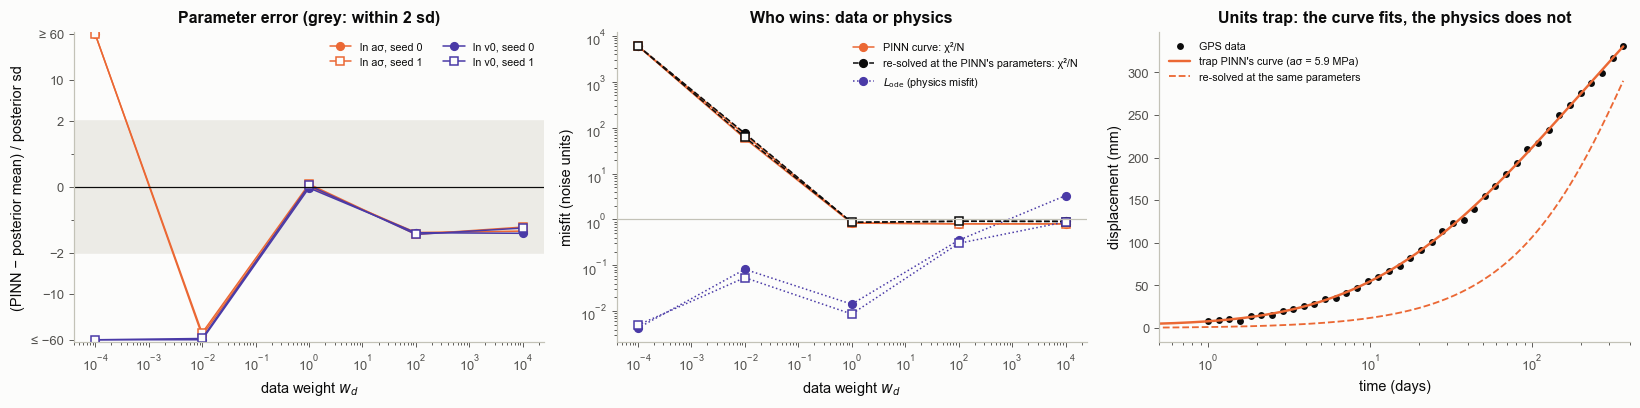

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
wv = np.array(W_ALL)
for j, (lab, c) in enumerate([("ln aσ", C_PINN), ("ln v0", C_LIN)]):
    for s, mk in [(0, "o"), (1, "s")]:
        z = [(res_w[w][s][0][j] - mu_post[j]) / sd_post[j] for w in W_ALL]
        axs[0].plot(wv, np.clip(z, -60, 60), mk + "-", color=c, ms=5, lw=1.0, mfc=c if s == 0 else S.SURFACE,
                    label=f"{lab}, seed {s}")
axs[0].axhspan(-2, 2, color="#ecebe6", zorder=0); axs[0].axhline(0, color=C_TRUE, lw=0.8)
axs[0].set_xscale("log"); axs[0].set_yscale("symlog", linthresh=2); axs[0].set_xlabel("data weight $w_d$")
axs[0].set_yticks([-60, -10, -2, 0, 2, 10, 60]); axs[0].set_yticklabels(["≤ −60", "−10", "−2", "0", "2", "10", "≥ 60"])
axs[0].set_ylabel("(PINN − posterior mean) / posterior sd"); axs[0].set_title("Parameter error (grey: within 2 sd)")
axs[0].legend(fontsize=7, loc="upper right", ncol=2)
for s, mk in [(0, "o"), (1, "s")]:
    axs[1].plot(wv, [res_w[w][s][2] for w in W_ALL], mk + "-", color=C_PINN, ms=5, lw=1.0, mfc=C_PINN if s == 0 else S.SURFACE,
                label="PINN curve: χ²/N" if s == 0 else None)
    axs[1].plot(wv, [chi_resolve(res_w[w][s][0]) for w in W_ALL], mk + "--", color=C_TRUE, ms=5, lw=1.0, mfc=C_TRUE if s == 0 else S.SURFACE,
                label="re-solved at the PINN's parameters: χ²/N" if s == 0 else None)
    axs[1].plot(wv, [res_w[w][s][1] for w in W_ALL], mk + ":", color=C_LIN, ms=5, lw=1.0, mfc=C_LIN if s == 0 else S.SURFACE,
                label="$L_\\mathrm{ode}$ (physics misfit)" if s == 0 else None)
axs[1].axhline(1, color=S.AXIS, lw=0.8)
axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].set_xlabel("data weight $w_d$"); axs[1].set_ylabel("misfit (noise units)")
axs[1].set_title("Who wins: data or physics"); axs[1].legend(fontsize=7, loc="upper right")
axs[2].plot(A.T_OBS * 365.25, 1e3 * d_obs, "o", ms=3.5, color=C_TRUE, label="GPS data")
axs[2].plot(tt * 365.25, 1e3 * u_trap_net, color=C_PINN, lw=1.6, label=f"trap PINN's curve (aσ = {np.exp(th_trap[0]):.1f} MPa)")
axs[2].plot(tt * 365.25, 1e3 * u_trap_phys, color=C_PINN, lw=1.2, ls="--", label="re-solved at the same parameters")
axs[2].set_xscale("log"); axs[2].set_xlim(0.5, 400); axs[2].set_xlabel("time (days)"); axs[2].set_ylabel("displacement (mm)")
axs[2].set_title("Units trap: the curve fits, the physics does not"); axs[2].legend(fontsize=7, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "3-04_loss_weights")
plt.show()

**How to read it.** Left: with a small data weight the parameters end far from the posterior (the symlog axis is
clipped at ±60 sd); at $w_d = 1$ they land on its centre; with very large weights they shift by more than one
posterior sd, the same way for both seeds, though still inside the grey band (values in the table above). The
small-weight failure is the optimiser's, not the loss's. With the parameters frozen at the posterior mean and only the
network trained, the $w_d = 10^{-4}$ loss ends far lower than in either free run (all three printed): its minimum is
near the right answer. Free to move, the parameters do something else. Started at the posterior mean, they stay
within a few sd while the network is still a rough curve, then drift away late in training while $L_\text{ode}$ falls
and χ²/N rises (printed): matching the parameters to the network's remaining imperfections lowers the heavily weighted
physics term, and the data term is too weak to object. Middle: the three misfits. At small $w_d$ the PINN satisfies the equation (small
$L_\text{ode}$) and ignores the data (large χ²/N). At large $w_d$ the PINN's curve fits the data *better than the
true model does* (χ²/N below the reference printed above): it is fitting noise, and the physics misfit grows to pay
for it. Re-solving at the PINN's parameters (dashed) is the honest number. Right: the units trap. Its loss equals the
section-5 loss at the true $a\sigma$, yet the optimiser moved to a much larger $a\sigma$ (printed), where an error in the
dimensionless slip costs less. The network's curve (solid) fits the data, but the physics at those parameters
(dashed) does not.

**The image to keep.** A PINN's loss is a misfit plus a physics regulariser with a weight, like a smoothing weight in a
slip inversion. Fukushima et al. (2025, p. 13) say it in those words: "the loss function which is optimized in our
PINNs framework is equivalent to a misfit function with a regularization term $L_\text{ode}$." And on choosing the
weight (2026, p. 19): "the choice of weight parameters is a challenging problem due to the complicated shape of the
loss function in the high-dimensional neural network parameter space. In this paper, instead of providing a solid
procedure to tune the hyperparameters, we just seek the weights by trial and error and find the appropriate parameters
where the PINN output satisfies both the governing equations and data fit." Their 2025 paper had started without
weights: "we start from the simple loss function without weight to avoid the ad hoc weight choice" (p. 6).

**Common misreadings.**
* "The equation is enforced." It is penalised, with a weight; it holds only approximately, and how approximately is
  a modelling choice (in Bayesian terms, a model-error variance; notebook 2.13).
* "Nondimensionalising is cosmetic." Section (b) shows it changes the answer once a parameter rescales the residual.
  Write every term in the units of the data noise, or check the answer by re-solving.

## 7. One answer, no error bar

**In plain words.** The inverse PINN returns one set of parameters. To see what that number is, repeat the whole
experiment on eight new noise realizations and compare each PINN answer with that realization's exact posterior.

**Precisely.** For noise realizations $k$ = 1…8: train the inverse PINN ($w_d$ = 1, start A, seed 0) and compute the
grid posterior; report (PINN − posterior mean)/posterior sd per parameter, and compare the scatter of the PINN answers
across realizations with the posterior sd. With a flat prior and a nearly Gaussian posterior, the maximum of the
posterior and its mean almost coincide, so a converged optimiser should land near the mean each time.
A Bayesian PINN (B-PINN) would instead place a probability distribution on the network weights and the parameters.
Fukushima et al. (2025, p. 10): "These results point to the importance of uncertainty quantification in the inversion
of frictional parameters to examine the reliability of the estimated parameters. A possible approach to address this
problem would be to resort to Bayesian Physics‐Informed Neural Networks (B‐PINNs) in which the NN parameters are treated
as probabilistic parameters (Yang et al., 2021)." We do not build one here.

In [16]:
N_REAL = 8
D_REAL = np.stack([d_clean + SIG * np.random.default_rng(100 + k).standard_normal(len(A.T_OBS)) for k in range(N_REAL)])
t0 = time.time()
train_real = jax.jit(jax.vmap(lambda d: train_inverse(1.0, 0, th0s[0], d)[:3]))
th_r, Lode_r, Ldat_r = [np.asarray(x) for x in train_real(jnp.asarray(D_REAL))]
print(f"{N_REAL} inverse PINNs in {time.time() - t0:.0f} s")
grids_r = [posterior_grid(D_REAL[k], TRUE[0], TRUE[1]) for k in range(N_REAL)]
mu_r = np.stack([g.mean for g in grids_r]); sd_r = np.stack([np.sqrt(np.diag(g.cov)) for g in grids_r])
z_r = (th_r - mu_r) / sd_r
for k in range(N_REAL):
    print(f"realization {k + 1}: PINN - posterior mean = {z_r[k, 0]:+.2f}, {z_r[k, 1]:+.2f} sd | L_ode {Lode_r[k]:.1e}, chi2/N {Ldat_r[k]:.3f}")
print(f"largest |PINN - posterior mean|: {np.abs(z_r).max():.2f} sd")
print(f"scatter of the PINN answers over realizations: {th_r[:, 0].std(ddof=1):.4f}, {th_r[:, 1].std(ddof=1):.4f}; "
      f"mean posterior sd {sd_r[:, 0].mean():.4f}, {sd_r[:, 1].mean():.4f}")
hdr90 = [g.levels[0.9] for g in grids_r]
dens_true = [g.P[np.abs(g.Y[:, 0] - TRUE[1]).argmin(), np.abs(g.X[0] - TRUE[0]).argmin()] for g in grids_r]
print("true value inside the exact 90 % region:", sum(dt_ >= h for dt_, h in zip(dens_true, hdr90)), "of", N_REAL, "realizations")
print("realizations with both offsets below 0.5 sd:", int(np.sum(np.all(np.abs(z_r) < 0.5, 1))), "of", N_REAL)

# the largest offset: unfinished training, or where this loss has its minimum? Retrain that realization.
k4 = int(np.argmax(np.abs(z_r).max(1)))
chi_min = lambda g, d: float(np.min(np.sum(((np.asarray(jax.vmap(lambda a, v: u_exact(jnp.stack([a, v, DTAU_KNOWN]), t_obs))(
    jnp.asarray(g.X.ravel()), jnp.asarray(g.Y.ravel()))) - d) / SIG) ** 2, 1)))
chi2_k4_min = chi_min(grids_r[k4], D_REAL[k4])
chi2_of = lambda th, d: float(np.sum(((np.asarray(u_exact(jnp.array([th[0], th[1], DTAU_KNOWN]), t_obs)) - d) / SIG) ** 2))
th_k4s = np.asarray(jax.jit(jax.vmap(lambda s: train_inverse(1.0, s, th0s[0], jnp.asarray(D_REAL[k4]))[0]))(jnp.arange(1, 3)))
th_k4l = np.asarray(jax.jit(lambda: train_inverse(1.0, 0, th0s[0], jnp.asarray(D_REAL[k4]), n=2 * N_STEPS)[0])())
z_k4 = np.vstack([(th_k4s - mu_r[k4]) / sd_r[k4], (th_k4l - mu_r[k4]) / sd_r[k4]])
print(f"realization {k4 + 1}, retrained: seeds 1-2 -> offsets {np.round(z_k4[:2], 2).tolist()} sd; "
      f"seed 0 with {2 * N_STEPS} steps -> {np.round(z_k4[2], 2).tolist()} sd")
print(f"   chi2 at the PINN answers minus the smallest chi2 on the grid: "
      f"{[round(chi2_of(t_, D_REAL[k4]) - chi2_k4_min, 2) for t_ in [th_r[k4], *th_k4s, th_k4l]]}")

8 inverse PINNs in 19 s


realization 1: PINN - posterior mean = +0.04, -0.02 sd | L_ode 4.6e-02, chi2/N 0.777
realization 2: PINN - posterior mean = +0.23, +0.22 sd | L_ode 3.0e-02, chi2/N 0.946
realization 3: PINN - posterior mean = -0.33, -0.34 sd | L_ode 3.2e-02, chi2/N 1.421
realization 4: PINN - posterior mean = -1.13, -0.96 sd | L_ode 2.0e-02, chi2/N 0.943
realization 5: PINN - posterior mean = +0.06, +0.05 sd | L_ode 6.7e-03, chi2/N 0.760
realization 6: PINN - posterior mean = +0.21, +0.13 sd | L_ode 5.6e-02, chi2/N 0.769
realization 7: PINN - posterior mean = -0.59, -0.53 sd | L_ode 1.7e-02, chi2/N 0.723
realization 8: PINN - posterior mean = -0.13, -0.11 sd | L_ode 7.6e-03, chi2/N 1.063
largest |PINN - posterior mean|: 1.13 sd
scatter of the PINN answers over realizations: 0.0075, 0.0256; mean posterior sd 0.0077, 0.0286
true value inside the exact 90 % region: 7 of 8 realizations
realizations with both offsets below 0.5 sd: 6 of 8


realization 4, retrained: seeds 1-2 -> offsets [[-1.05, -0.89], [-1.02, -0.87]] sd; seed 0 with 40000 steps -> [-1.07, -0.91] sd
   chi2 at the PINN answers minus the smallest chi2 on the grid: [1.95, 1.77, 1.68, 1.83]


saved figures/3-04_uncertainty.png


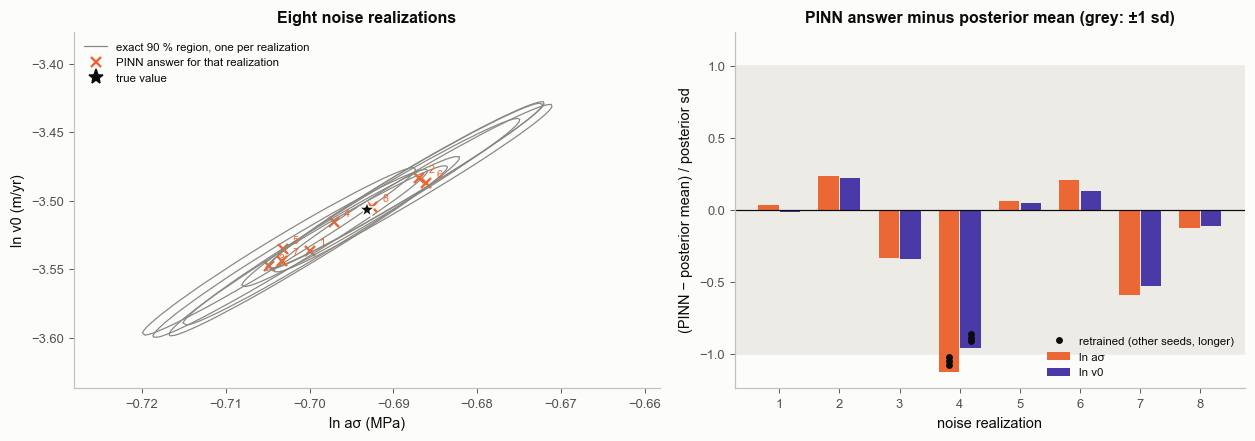

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.1), gridspec_kw=dict(width_ratios=[1.15, 1]))
ax = axs[0]
for k, g in enumerate(grids_r):
    ax.contour(g.X, g.Y, g.P, levels=[P.hdr_levels(g.P, (0.9,))[0.9]], colors=S.MUTED, linewidths=0.8)
    ax.plot(th_r[k, 0], th_r[k, 1], "x", color=C_PINN, ms=7, mew=1.6)
    ax.text(th_r[k, 0] + 0.0012, th_r[k, 1] + 0.004, str(k + 1), fontsize=7, color=C_PINN)
ax.plot(TRUE[0], TRUE[1], "*", color=C_TRUE, ms=11, mec=S.SURFACE)
ax.plot([], [], color=S.MUTED, lw=0.8, label="exact 90 % region, one per realization")
ax.plot([], [], "x", color=C_PINN, mew=1.6, label="PINN answer for that realization")
ax.plot([], [], "*", color=C_TRUE, ms=10, label="true value")
ax.set_xlim(TRUE[0] - 0.035, TRUE[0] + 0.035); ax.set_ylim(TRUE[1] - 0.13, TRUE[1] + 0.13)
ax.set_xlabel("ln aσ (MPa)"); ax.set_ylabel("ln v0 (m/yr)"); ax.set_title("Eight noise realizations")
ax.legend(fontsize=7.5, loc="upper left")
ax = axs[1]
xk = np.arange(1, N_REAL + 1)
ax.bar(xk - 0.18, z_r[:, 0], width=0.34, color=C_PINN, label="ln aσ")
ax.bar(xk + 0.18, z_r[:, 1], width=0.34, color=C_LIN, label="ln v0")
ax.plot(np.full(3, k4 + 1 - 0.18), z_k4[:, 0], "o", color=C_TRUE, ms=3.5, zorder=4, label="retrained (other seeds, longer)")
ax.plot(np.full(3, k4 + 1 + 0.18), z_k4[:, 1], "o", color=C_TRUE, ms=3.5, zorder=4)
ax.axhspan(-1, 1, color="#ecebe6", zorder=0); ax.axhline(0, color=C_TRUE, lw=0.8)
ax.set_ylim(-max(1.2, 1.1 * np.abs(z_r).max()), max(1.2, 1.1 * np.abs(z_r).max()))
ax.set_xlabel("noise realization"); ax.set_ylabel("(PINN − posterior mean) / posterior sd")
ax.set_title("PINN answer minus posterior mean (grey: ±1 sd)"); ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "3-04_uncertainty")
plt.show()

**How to read it.** Left: each grey contour is one realization's exact 90 % region; the PINN answer (orange x) sits
inside it every time. Right: most offsets are well below half a posterior sd (count printed above), but one
realization is off by about one sd, along the valley where the data constrain the parameters least. Retraining that
realization with other seeds and with twice as many steps lands in the same place (black dots, printed above),
and the closed form at those answers fits the data worse than the best fit by the χ² differences printed. So this
offset is not unfinished training: it is where this loss has its minimum. With $w_d = 1$ the network may bend away
from the equation by about one σ per e-fold of time, and that freedom absorbs part of the data. A converged inverse
PINN is therefore a best-fit estimator with a small bias of its own: its answer moves from realization to realization
by about the posterior width (scatter printed above), but any single run reports no width at all. The posterior, from
NUTS or the grid, is what tells you how far to trust it.

**Common misreadings.**
* "Train several PINNs and take their spread." Over network seeds the spread is far smaller than the posterior
  (section 5); over data realizations it is about right but needs data you do not have. Uncertainty needs a
  posterior: a B-PINN, a Laplace approximation at the PINN answer (notebook 2.08), or a sampler on the physics.

## 8. When PINNs help, and when they do not

Costs measured in this notebook (this Mac, other jobs running; wall-clock numbers are rough):

In [18]:
print(f"one black-box solve (diffrax)                      {1e3 * T_SOLVE:8.1f} ms")
print(f"forward PINN, one curve ({N_STEPS} Adam steps)        {T_PINN_FWD:8.1f} s")
print(f"inverse PINN, {len(cfg)} runs in parallel                  {T_INV:8.1f} s")
print(f"NUTS through the black box (2 chains x 500 iterations) {T_NUTS:8.1f} s")

one black-box solve (diffrax)                           2.6 ms
forward PINN, one curve (20000 Adam steps)             4.0 s
inverse PINN, 7 runs in parallel                      18.1 s
NUTS through the black box (2 chains x 500 iterations)     48.5 s


For context, Fukushima et al. (2025) report for their 3-D slow-slip PINN: "Optimization for 20,000 iterations took
∼13 hr by using GPU (NVIDIA RTX A6000)" (p. 7) with slip-rate data, and "Optimization for 40,000 iterations took ∼27 hr
by using GPU (NVIDIA RTX A6000)" (p. 9) with surface data.

| situation | PINN | classical route |
|---|---|---|
| cheap, accurate solver, few parameters (this notebook) | slower and less accurate than the solver; one answer, no error bar | solver + NUTS (or a grid) gives the posterior directly |
| stiff or multiscale dynamics | fails unless the coordinates are chosen well (sections 3-4) | adaptive implicit solvers handle it routinely |
| parameters form a *field* (friction varying over a fault) | a network represents the field compactly: "PINNs employ a neural network to represent the spatially variable frictional properties, making their estimation feasible" (Fukushima et al. 2026, p. 1) | many parameters need gradients: adjoints or autodiff (2.22), or an ensemble method (06, 2.26) |
| no adjoint code (2.22), solver hard to differentiate | the PINN only needs derivatives of a network, which autodiff gives for free | finite differences or ensemble methods |
| initial state also unknown | estimated with the parameters: "Simultaneous inversion of frictional parameters and initial state variables is possible with the appropriate prior information" (Fukushima et al. 2025, p. 1) | add the state to the unknowns of a solver-based inversion |
| calibrated uncertainty needed | needs a B-PINN, at much higher cost (Fukushima et al. 2025, p. 10) | samplers (2.16-2.20) or ensemble Kalman methods (2.24) |

**Where PINNs sit among the routes.** A PINN does not learn a surrogate that can be reused for new parameters (that
is 3.01-3.03 and the neural operators of 3.05): it solves *one* inverse problem, with the physics as a weighted
regulariser. Its error, the residual it leaves in the equation, is model error in the sense of 2.13: it enters the
answer whether or not it is accounted for.

**In practice.**
* In stress-driven afterslip the forward map is close to exponential in $\ln v_0$ and $a\sigma$; the thin, curved
  valley of section 5 is that exponential sensitivity in two dimensions, and it is what makes gradient steps and
  ensemble updates delicate for this model class.
* If $a\sigma$ varies over the fault, the unknown is a field, which is the case Fukushima et al. built PINNs for. The
  checks of this notebook carry over: write every loss term in units of the data noise, choose a time coordinate in
  which the solution is smooth, re-solve with the trusted forward model at the PINN's answer, and get the uncertainty
  from a posterior, not from the spread of repeated trainings.

Next: [**3.05 · Neural operators (FNO)**](3-05_neural_operators_fno.ipynb).

In [19]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 180 s
